
# Logistic Regression — Gentle Intro (Health) — *With Error Rate & Wooclap Cues*

**What’s inside**
- Contrast with `LinearRegression`
- Shuffled data
- Error rate (% wrong) metric
- Clear **Wooclap launch cues**
- **Sanity check** cell (seed only, no reference answer shown)


## 0) Setup

In [1]:

# If needed in Colab:
# !pip install -q numpy matplotlib scikit-learn
import numpy as np
import matplotlib.pyplot as plt
from sklearn.linear_model import LogisticRegression, LinearRegression
np.random.seed(42)



## 1) Data (Health scenario)

Binary outcome **heart disease** (0/1) from **cholesterol** (mg/dL).


In [3]:

# Cholesterol values (mg/dL)
chol = np.array([150,160,170,180,190,195,200,205,210,215,220,230,240,250,260,270,280]).reshape(-1, 1)

# Hidden "true" probability increasing with cholesterol
def true_prob(c):
    return 1 / (1 + np.exp(-(c - 210)/15))

probs = true_prob(chol)
# Sample binary labels
y = (np.random.rand(len(probs)) < probs.flatten()).astype(int)

# Shuffle
idx = np.random.permutation(len(chol))
X = chol[idx]
y = y[idx]

X[:5].flatten(), y[:10] #.flatten( turns a NumPy array into a 1D array, 


(array([190, 170, 220, 150, 210]), array([0, 0, 0, 0, 0, 1, 1, 1, 1, 1]))


## 2) Visualize the raw data

**Task:** Scatter plot cholesterol vs. disease (0/1).

**🎯 Wooclap cue:** After the plot → **[WQ1 – MCQ]** Why logistic for 0/1?


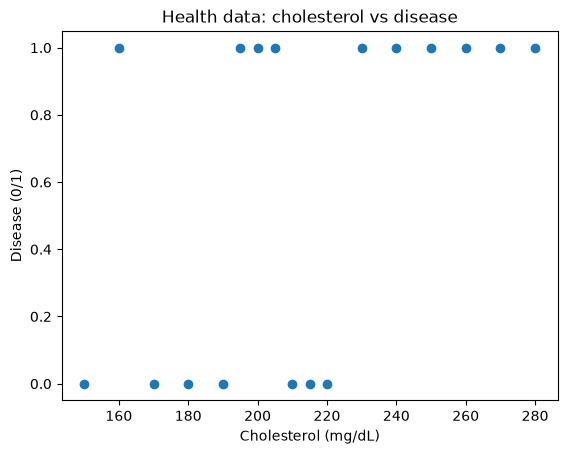

In [5]:

# TODO: scatter plot
plt.scatter(X, y)
plt.xlabel("Cholesterol (mg/dL)")
plt.ylabel("Disease (0/1)")
plt.title("Health data: cholesterol vs disease")
plt.show()



## 3) (Contrast) Linear regression on 0/1 targets

**Task:** Fit `LinearRegression()` and overlay on the scatter.

**🎯 Wooclap cue:** After the plot → **[WQ3 – MCQ]** Default decision rule?


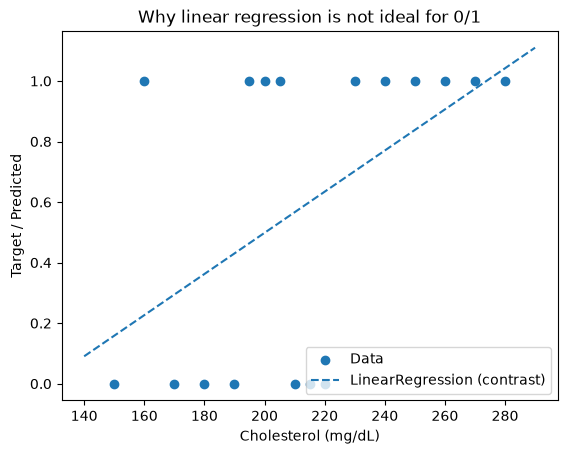

In [6]:

# TODO: LinearRegression contrast
lin = LinearRegression()
lin.fit(X, y)
grid = np.linspace(X.min()-10, X.max()+10, 200).reshape(-1, 1)
y_lin = lin.predict(grid)
plt.scatter(X, y, label="Data")
plt.plot(grid, y_lin, label="LinearRegression (contrast)", linestyle="--")
plt.xlabel("Cholesterol (mg/dL)")
plt.ylabel("Target / Predicted")
plt.title("Why linear regression is not ideal for 0/1")
plt.legend(); plt.show()



## 4) Logistic regression: fit and visualize

**Task A:** Fit `LogisticRegression()`  
**Task B:** Plot `predict_proba(grid)[:, 1]` (sigmoid)

**🎯 Wooclap cue:** After computing `predict_proba` → **[WQ2 – MCQ]** What does it return?


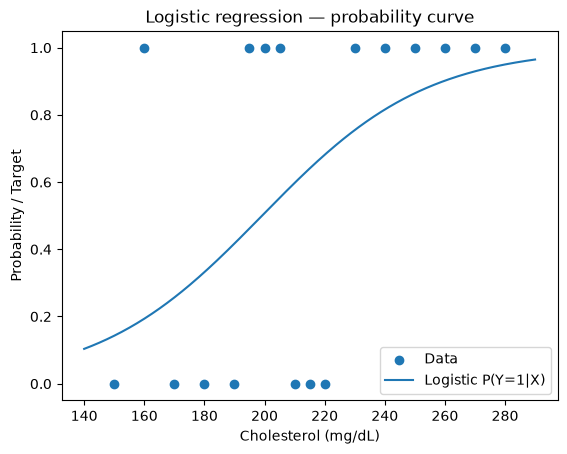

In [8]:

# TODO: LogisticRegression fit + sigmoid plot
model = LogisticRegression()
model.fit(X, y)
grid = np.linspace(X.min()-10, X.max()+10, 300).reshape(-1, 1)
probs_hat = model.predict_proba(grid)[:, 1]
plt.scatter(X, y, label="Data")
plt.plot(grid, probs_hat, label="Logistic P(Y=1|X)")
plt.xlabel("Cholesterol (mg/dL)"); plt.ylabel("Probability / Target")
plt.title("Logistic regression — probability curve")
plt.legend(); plt.show()




## 5) Decision rule (threshold) + Error rate

By default classify **1** if probability ≥ **0.5**, else **0**.

**Task A:** `y_proba = model.predict_proba(X)[:, 1]`  
**Task B:** `y_pred_05 = (y_proba >= 0.5).astype(int)`  
**Task C:** `error_rate = 100 * np.mean(y_pred_05 != y)` → print one decimal

**🎯 Wooclap cue:** After printing `error_rate` → **[WQ4 – GuessNumber]** Enter your error rate @0.5.


In [9]:

# TODO: compute probabilities, predictions, error rate
y_proba = model.predict_proba(X)[:, 1]
y_pred_05 = (y_proba >= 0.5).astype(int)
error_rate = 100 * np.mean(y_pred_05 != y)
print(f"Error rate @0.5: {error_rate:.1f}%")
print("True y (first 10): ", y[:10])
print("Pred @0.5 (first 10):", y_pred_05[:10])


Error rate @0.5: 29.4%
True y (first 10):  [0 0 0 0 0 1 1 1 1 1]
Pred @0.5 (first 10): [0 0 1 0 1 1 1 1 1 1]



### Sanity check (seed only)

If your error rate looks off compared to the teacher’s reference on Wooclap, you can verify your random seed here.

> This does **not** reveal the expected error rate (to keep Wooclap meaningful).


In [10]:

# Seed-only sanity check
print("Sanity check — random seed:", 42)
# If your error rate differs from the class reference, check that you haven't modified earlier cells.


Sanity check — random seed: 42



## 6) Threshold sweep (qualitative)

Try thresholds 0.3 and 0.7, recompute error rate, and compare.

**🎯 Wooclap cue:** After this section → **[WQ6 – Open]** Why choose a lower threshold in screening?


In [11]:

# TODO: threshold sweep
for thr in [0.3, 0.5, 0.7]:
    y_pred_thr = (y_proba >= thr).astype(int)
    err = 100 * np.mean(y_pred_thr != y)
    print(f"Threshold = {thr} | Error rate: {err:.1f}%")


Threshold = 0.3 | Error rate: 35.3%
Threshold = 0.5 | Error rate: 29.4%
Threshold = 0.7 | Error rate: 23.5%



## 7) Short reflections
- Why is logistic regression more appropriate than linear regression for 0/1 outcomes?

-> Parce que la variable cible est binaire : elle ne peut prendre que 0 ou 1 alors que la régression linéaire n'est pas adaptée à des sorties binaires

- What does `predict_proba` return (plain words)?

-> it gives the probability to belong to each classe (either 1 or 0)

- In a health context, when might you choose a **lower** threshold than 0.5?

-> to detect more potential cases
